# XGBoost detector for BATADAL

Supervised XGBoost after Nemade et al. (2026): 400 trees, depth 6, learning rate 0.05, 0.8 row/column subsampling, `scale_pos_weight` = negatives / positives; lag, difference, rolling and time features.

**Labels.** Dataset 1 = normal (negatives). Dataset 2 `ATT_FLAG = 1` = attack hours (positives, 219 h). `ATT_FLAG = -999` rows are dropped: never a training or hour-level evaluation label (the ones inside a real attack window are scored only to measure detection delay).

**Protocol.** Leave-one-attack-out over the 5 attacks that have labeled hours; attacks 2 and 7 have none, so no model trains on them. Thresholds come from the calibration block (budget: <= 1 false-alarm episode/week and <= 1% of hours); false alarms are counted on the validation block. Run from this folder (`models/XGBoost/`); needs `xgboost`, `pandas`, `numpy`, `matplotlib`.

In [1]:
import sys, json, pathlib, argparse
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
sys.path.insert(0, '.')
from xgb_data import load_blocks, WARMUP
from train_xgboost import run_seed, PAPER_PARAMS
pd.set_option('display.width', 200)

DATA_DIR = pathlib.Path('../../data/processed')
OUT_DIR = pathlib.Path('notebook_outputs')
SEEDS = [0, 1, 2]

## 1. Data and features

In [2]:
blocks = load_blocks(str(DATA_DIR))
feats, meta = blocks['d2']
print('features:', blocks['train'][0].shape[1])
print({k: len(v[0]) for k, v in blocks.items()}, f'(first {WARMUP} rows of every block dropped)')
flag = meta.att_flag.value_counts().to_dict()
print('Dataset 2 ATT_FLAG counts:', flag)
per = meta[meta.attack_id > 0].groupby('attack_id').agg(real_hours=('att_flag', 'size'), labeled=('att_flag', lambda s: int((s == 1).sum())))
per

features: 391
{'train': 5233, 'val': 1705, 'cal': 1706, 'd2': 4154} (first 23 rows of every block dropped)
Dataset 2 ATT_FLAG counts: {-999: 3935, 1: 219}


,real_hours,labeled
attack_id,,
1,50,42
2,24,0
3,60,60
4,94,37
5,60,7
6,94,73
7,110,0


In [3]:
cols = list(blocks['train'][0].columns)
families = {'raw': [c for c in cols if not any(t in c for t in ('_lag', '_diff', '_r')) and not c.startswith(('hour_', 'dow_'))],
            'lag': [c for c in cols if '_lag' in c], 'diff': [c for c in cols if '_diff' in c],
            'rolling': [c for c in cols if '_r' in c and not c.startswith(('hour_', 'dow_'))],
            'time': [c for c in cols if c.startswith(('hour_', 'dow_'))]}
pd.Series({k: len(v) for k, v in families.items()}, name='columns')

raw         36
lag        108
diff        72
rolling    171
time         4
Name: columns, dtype: int64

## 2. Train, calibrate and evaluate (3 seeds)

Each seed trains one model per held-out attack plus a final model on all 219 positives.

In [4]:
args = argparse.Namespace(n_estimators=PAPER_PARAMS['n_estimators'], max_depth=PAPER_PARAMS['max_depth'],
                         learning_rate=PAPER_PARAMS['learning_rate'], n_jobs=-1,
                         max_alarm_fraction=0.01, max_episodes_per_week=1.0)
results = {}
for seed in SEEDS:
    metrics, per_attack = run_seed(blocks, args, str(OUT_DIR / f'seed{seed}'), seed)
    results[seed] = (metrics, pd.DataFrame(per_attack))
    print(f"seed {seed}: detected {metrics['attacks_detected']}/7, recall {metrics['recall']:.3f}, TNR {metrics['true_negative_rate']:.4f}, ROC {metrics['roc_auc']:.3f}, PR {metrics['pr_auc']:.3f}, S {metrics['s_score']:.3f}")

seed 0: detected 4/7, recall 0.279, TNR 0.9935, ROC 0.668, PR 0.464, S 0.557


seed 1: detected 4/7, recall 0.269, TNR 0.9939, ROC 0.674, PR 0.469, S 0.546


seed 2: detected 4/7, recall 0.279, TNR 0.9940, ROC 0.672, PR 0.463, S 0.545


## 3. Results

In [5]:
keys = ['attacks_detected', 'unseen_detected', 'mean_delay_hours', 'recall', 'precision', 'f1', 'true_negative_rate', 'val_false_alarm_episodes_per_week', 'roc_auc', 'pr_auc', 's_ttd', 's_clf', 's_score']
table = pd.DataFrame({f'seed{s}': {k: m[k] for k in keys} for s, (m, _) in results.items()})
table['mean'] = table.mean(axis=1)
table.round(3)

,seed0,seed1,seed2,mean
attacks_detected,4.000,4.000,4.000,4.000
unseen_detected,1.000,1.000,1.000,1.000
mean_delay_hours,9.500,11.500,11.750,10.917
recall,0.279,0.269,0.279,0.275
precision,0.847,0.851,0.857,0.852
f1,0.419,0.409,0.420,0.416
true_negative_rate,0.994,0.994,0.994,0.994
val_false_alarm_episodes_per_week,0.624,0.575,0.640,0.613
roc_auc,0.668,0.674,0.672,0.672
pr_auc,0.464,0.469,0.463,0.465


In [6]:
results[0][1]

,attack,real_hours,labeled_hours,scored_by,threshold,detected,delay_hours,labeled_hours_alarmed,recall_on_labeled,window_hours_alarmed
0,1,50,42,fold1,0.008023,False,NaN,0,0.000000,0
1,2,24,0,final,0.014406,True,3.0,0,NaN,18
2,3,60,60,fold3,0.004992,True,17.0,25,0.416667,25
3,4,94,37,fold4,0.020594,True,10.0,36,0.972973,71
4,5,60,7,fold5,0.007272,True,8.0,0,0.000000,12
5,6,94,73,fold6,0.014074,False,NaN,0,0.000000,0
6,7,110,0,final,0.014406,False,NaN,0,NaN,0


`scored_by` shows which model scored each attack: a fold model that never saw that attack, or the final model for attacks 2 and 7 (no labeled hours). The precision depends on the arbitrary mix of 219 positives to 1,705 validation hours.

In [7]:
pd.read_csv(OUT_DIR / 'seed0' / 'folds.csv').round(4)

,model,n_pos_train,threshold,cal_alarm_fraction,cal_episodes_per_week,val_alarm_fraction,val_episodes_per_week
0,fold1,177,0.0080,0.0076,0.9848,0.0023,0.3941
1,fold3,159,0.0050,0.0100,0.8863,0.0106,0.7883
2,fold4,182,0.0206,0.0094,0.9848,0.0047,0.4927
3,fold5,212,0.0073,0.0100,0.8863,0.0076,0.7883
4,fold6,146,0.0141,0.0094,0.9848,0.0094,0.8868
5,final,219,0.0144,0.0082,0.9848,0.0041,0.3941


## 4. Per-attack scores and feature importance (seed 0)

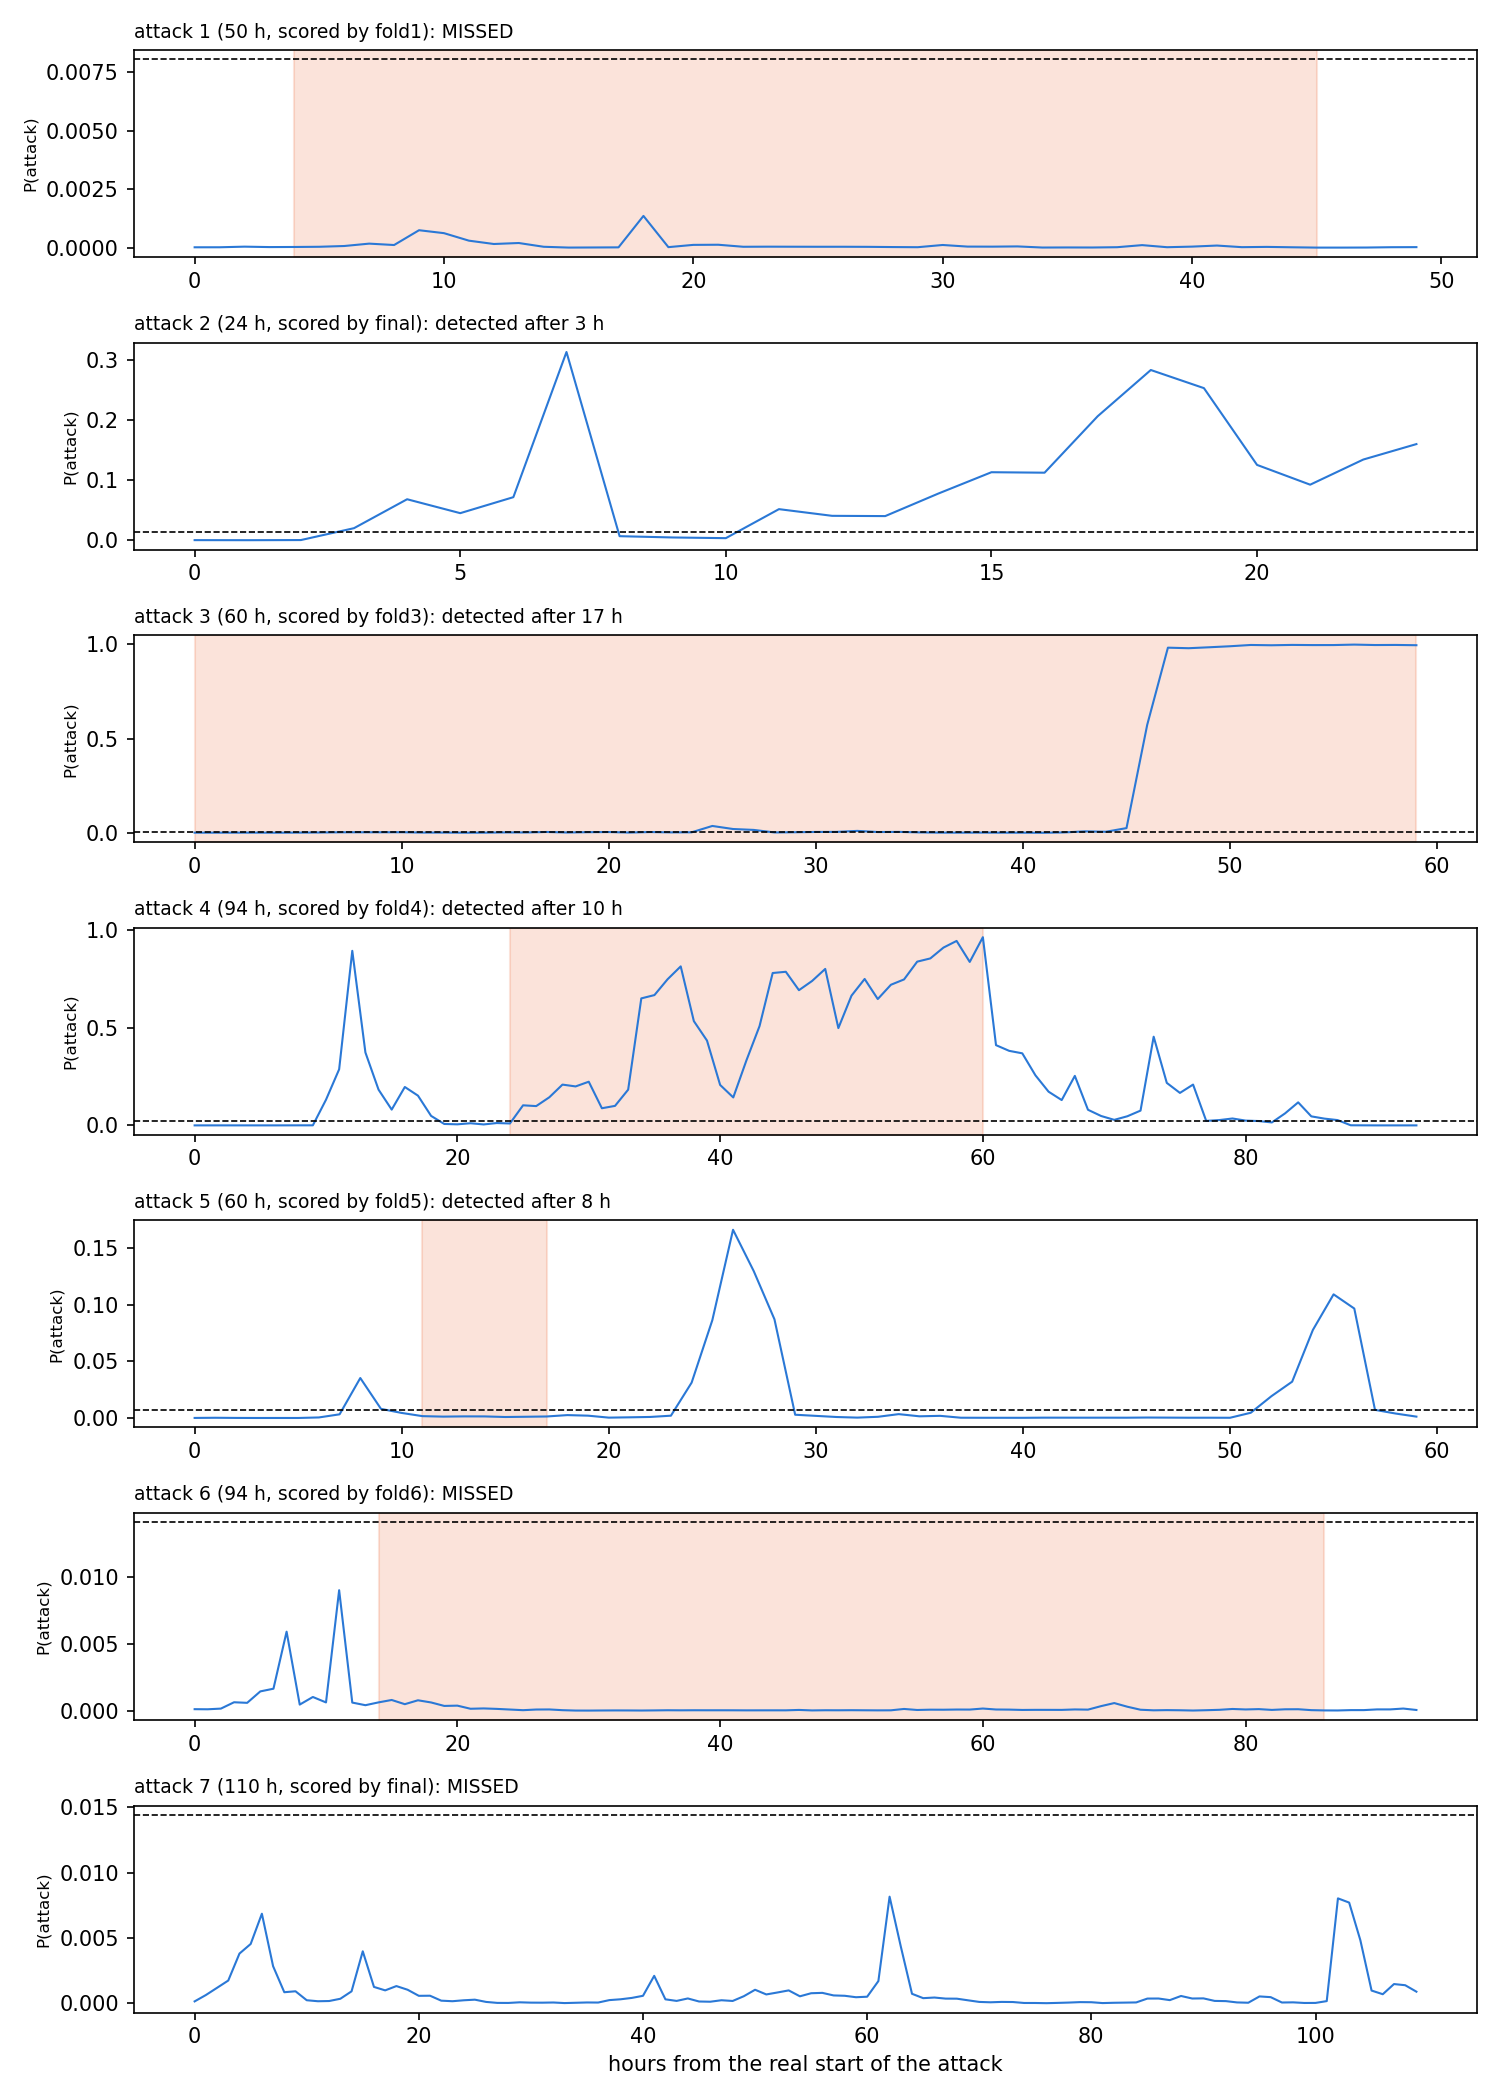

In [8]:
display(Image(str(OUT_DIR / 'seed0' / 'attack_scores.png')))

In [9]:
imp = pd.read_csv(OUT_DIR / 'seed0' / 'feature_importance.csv', index_col=0)['gain']
imp.head(20)[::-1].plot.barh(figsize=(6, 5), title='Top 20 features by gain (final model, seed 0)'); plt.tight_layout()
imp.groupby(lambda c: next((k for k, v in families.items() if c in v), 'other')).sum().div(imp.sum()).round(3).sort_values(ascending=False)

rolling    0.523
lag        0.233
raw        0.152
time       0.052
diff       0.039
Name: gain, dtype: float64

## 5. Saved outputs

`notebook_outputs/seed<k>/`: `metrics.json`, `per_attack.csv`, `folds.csv`, `xgb_hourly_scores.csv` (input to `models/Ensemble/ensemble.py`), `feature_importance.csv/.png`, `attack_scores.png`, `final_model.json` (XGBoost model trained on all 219 positives).

In [10]:
sorted(p.name for p in (OUT_DIR / 'seed0').iterdir())

['attack_scores.png',
 'feature_importance.csv',
 'feature_importance.png',
 'final_model.json',
 'folds.csv',
 'metrics.json',
 'per_attack.csv',
 'xgb_hourly_scores.csv']